# Epoch 0: pretrained CordsNet-R8 vs monkey F

Frozen pretrained model, val split (same images as monkey N), batches of 64 from one F recording day.
CKA_S (Song et al. 2012) per model layer, brain area and 10 ms bin, pooled over batches (H values averaged first, then one ratio).

- Monkey F data: V4 and IT files swapped back (`clean_monkeyF.py`), all electrodes kept
- Response windows: TVSD window start (bin containing it) to 200 ms: V1 20-200 ms, V4 50-200 ms, IT 70-200 ms
- Error bars / bands: SE from 1,000 bootstrap resamples of the batches
- NaN = undefined (deep layers in the first bins)

Inputs: `Round1/outputs/epoch0_pretrained_monkeyF/results.npz`; last figure also `outputs/epoch0_pretrained/results.npz` (monkey N).

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=RuntimeWarning)   # nanmean over all-NaN bins, 0/0 in undefined bins

ROUND1 = Path("~/Desktop/DynVision/CordsNet/Round1").expanduser()
res = {"monkeyF": np.load(ROUND1 / "outputs" / "epoch0_pretrained_monkeyF" / "results.npz"),
       "monkeyN": np.load(ROUND1 / "outputs" / "epoch0_pretrained" / "results.npz")}

r = res["monkeyF"]
layers, areas, ests = [[str(x) for x in r[k]] for k in ("layers", "areas", "estimators")]
S = ests.index("CKA_S")
t_ms = r["bin_start_ms"] + 5                                   # bin centers
days = r["batch_day"]
h_num, h_dm, h_dn = r["h_num"][..., 1], r["h_den_model"][..., 1], r["h_den_neural"][..., 1]   # Song terms
cka = r["cka_pooled"][..., S]                                  # (layer, area, bin)

window = {"V1": np.arange(2, 20), "V4": np.arange(5, 20), "IT": np.arange(7, 20)}
win_mean = np.array([[np.nanmean(cka[i, j, window[a]]) for j, a in enumerate(areas)] for i in range(len(layers))])
best = {a: int(np.nanargmax(win_mean[:, j])) for j, a in enumerate(areas)}

# bootstrap over batches: resample batches, pool H values, recompute CKA_S
rng = np.random.default_rng(0)
n_b, n_boot = h_num.shape[0], 1000
boot = np.zeros((n_boot, len(layers), len(areas), 20))
for k in range(n_boot):
    idx = rng.integers(0, n_b, n_b)
    boot[k] = h_num[idx].mean(0) / np.sqrt(h_dm[idx].mean(0)[:, None] * h_dn[idx].mean(0)[None])
se_t = np.nanstd(boot, axis=0)                                  # per bin (layer, area, bin)
se_w = np.nanstd(np.stack([np.nanmean(boot[:, :, j, window[a]], axis=-1) for j, a in enumerate(areas)], -1), axis=0)

layer_color = plt.cm.viridis(np.linspace(0, 0.92, len(layers)))   # layer1 dark purple ... layer8 yellow-green
area_color = {"V1": "#2a78d6", "V4": "#eb6834", "IT": "#1baf7a"}
day_color = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

print(f"{n_b} batches; batches per day:", {int(d): int((days == d).sum()) for d in np.unique(days)})
print("best layer (CKA_S, response window):", {a: layers[i] for a, i in best.items()})

27 batches; batches per day: {1: 5, 2: 8, 3: 8, 4: 6}
best layer (CKA_S, response window): {'V1': 'layer2', 'V4': 'layer2', 'IT': 'layer7'}


## 1. Which layer matches each area?

CKA_S averaged over the response window, per layer.

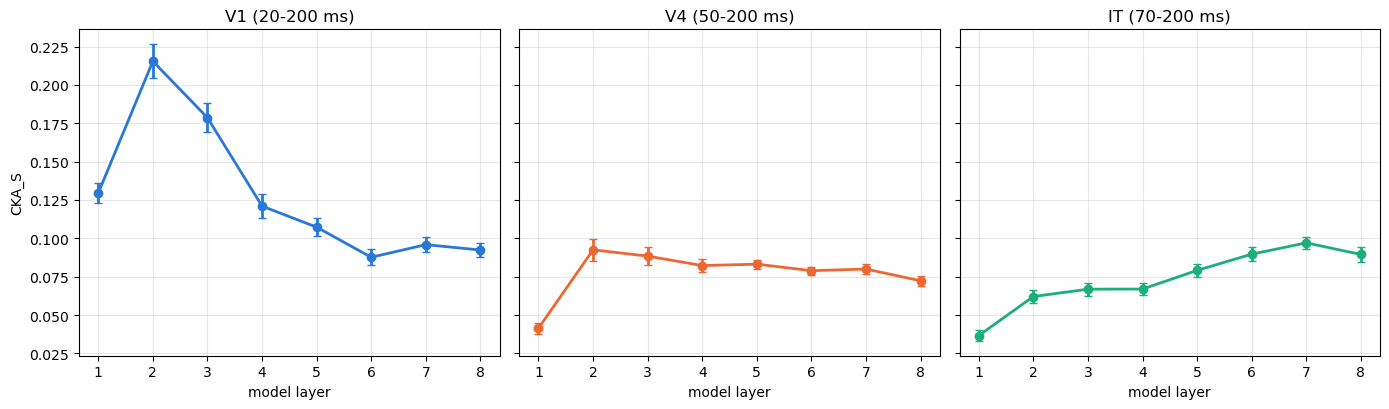

V1: best layer2 (0.215 +- 0.011)   0.130  0.215  0.179  0.121  0.107  0.088  0.096  0.092
V4: best layer2 (0.093 +- 0.007)   0.041  0.093  0.088  0.082  0.083  0.079  0.080  0.072
IT: best layer7 (0.097 +- 0.004)   0.037  0.062  0.067  0.067  0.079  0.090  0.097  0.090


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for j, area in enumerate(areas):
    axes[j].errorbar(range(1, 9), win_mean[:, j], yerr=se_w[:, j], fmt="o-", color=area_color[area], lw=2, ms=6, capsize=3)
    axes[j].set(title=f"{area} ({window[area][0] * 10}-200 ms)", xlabel="model layer", xticks=range(1, 9))
    axes[j].grid(alpha=0.3)
axes[0].set_ylabel("CKA_S")
plt.tight_layout()
plt.show()

for j, area in enumerate(areas):
    i = best[area]
    print(f"{area}: best {layers[i]} ({win_mean[i, j]:.3f} +- {se_w[i, j]:.3f})   " + "  ".join(f"{v:.3f}" for v in win_mean[:, j]))

## 2. CKA_S over time, all layers

Gray: response window.

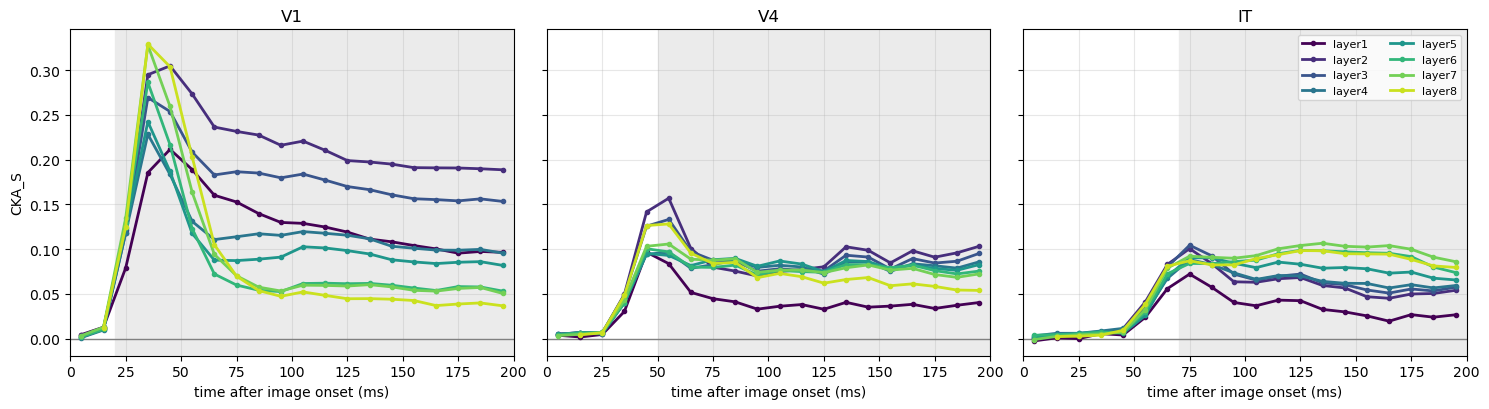

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for j, area in enumerate(areas):
    ax = axes[j]
    ax.axvspan(window[area][0] * 10, 200, color="0.92", zorder=0)
    ax.axhline(0, color="0.5", lw=1)
    for i, layer in enumerate(layers):
        ax.plot(t_ms, cka[i, j], "o-", color=layer_color[i], lw=2, ms=3, label=layer)
    ax.set(title=area, xlabel="time after image onset (ms)", xlim=(0, 200))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("CKA_S")
axes[-1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 3. Best layer over time

Top: CKA_S of the best layer (response window) per bin, band = ±1 SE.
Bottom: the layer with the highest CKA_S in each bin.

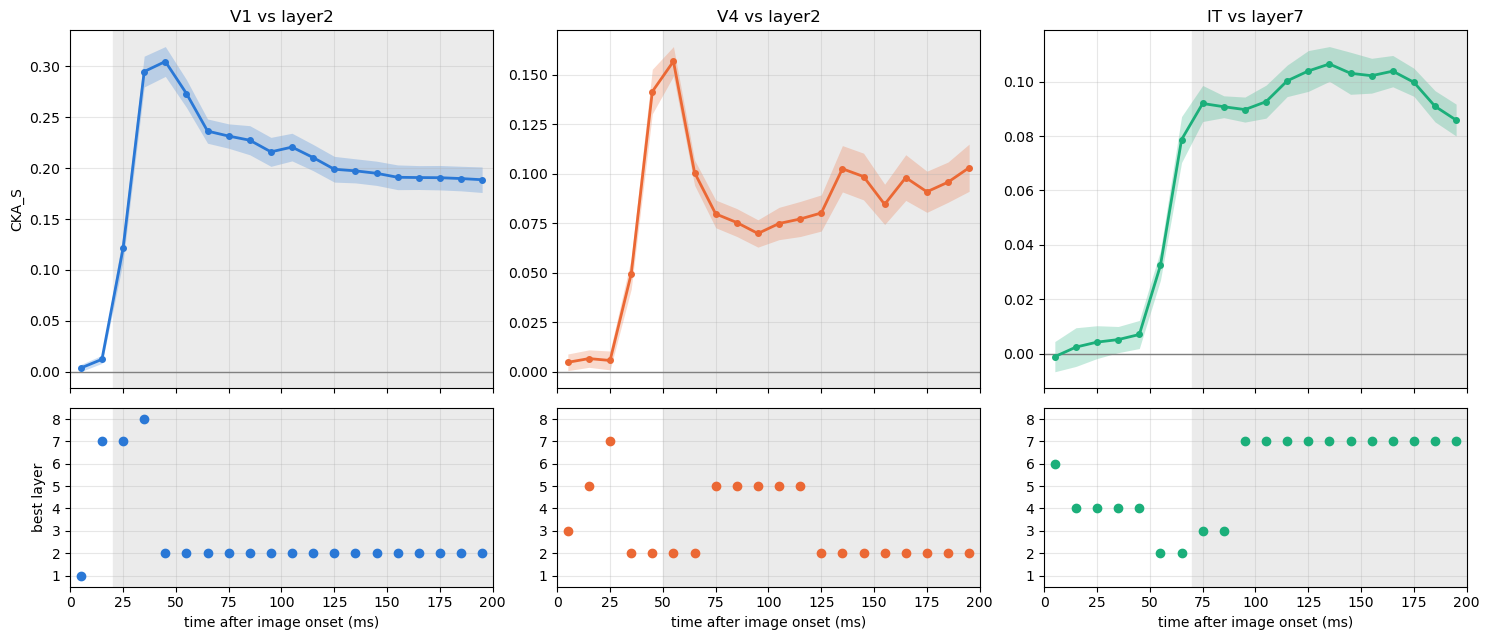

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for j, area in enumerate(areas):
    i = best[area]
    ax = axes[0, j]
    ax.axvspan(window[area][0] * 10, 200, color="0.92", zorder=0)
    ax.axhline(0, color="0.5", lw=1)
    ax.fill_between(t_ms, cka[i, j] - se_t[i, j], cka[i, j] + se_t[i, j], color=area_color[area], alpha=0.25, lw=0)
    ax.plot(t_ms, cka[i, j], "o-", color=area_color[area], lw=2, ms=4)
    ax.set(title=f"{area} vs {layers[i]}", xlim=(0, 200))
    ax.grid(alpha=0.3)

    top = np.full(20, np.nan)
    ok = ~np.all(np.isnan(cka[:, j]), axis=0)
    top[ok] = np.nanargmax(cka[:, j][:, ok], axis=0) + 1
    axes[1, j].axvspan(window[area][0] * 10, 200, color="0.92", zorder=0)
    axes[1, j].plot(t_ms, top, "o", color=area_color[area], ms=6)
    axes[1, j].set(xlabel="time after image onset (ms)", ylim=(0.5, 8.5), yticks=range(1, 9))
    axes[1, j].grid(alpha=0.3)
axes[0, 0].set_ylabel("CKA_S")
axes[1, 0].set_ylabel("best layer")
plt.tight_layout()
plt.show()

## 4. Check: consistency across recording days

Best layer per area, CKA_S pooled over the batches of each F day separately.

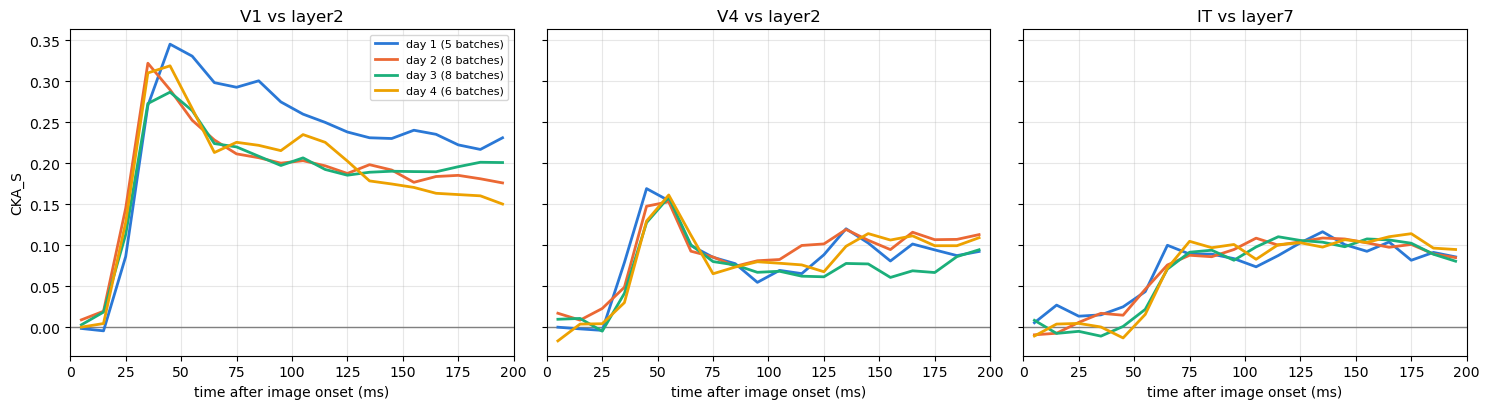

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for j, area in enumerate(areas):
    i = best[area]
    axes[j].axhline(0, color="0.5", lw=1)
    for k, d in enumerate(np.unique(days)):
        sel = days == d
        y = h_num[sel, i, j].mean(0) / np.sqrt(h_dm[sel, i].mean(0) * h_dn[sel, j].mean(0))
        axes[j].plot(t_ms, y, "-", color=day_color[k], lw=2, label=f"day {d} ({sel.sum()} batches)")
    axes[j].set(title=f"{area} vs {layers[i]}", xlabel="time after image onset (ms)", xlim=(0, 200))
    axes[j].grid(alpha=0.3)
axes[0].set_ylabel("CKA_S")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Summary: monkey F vs monkey N

CKA_S averaged over the response window (same windows for both monkeys), per layer.

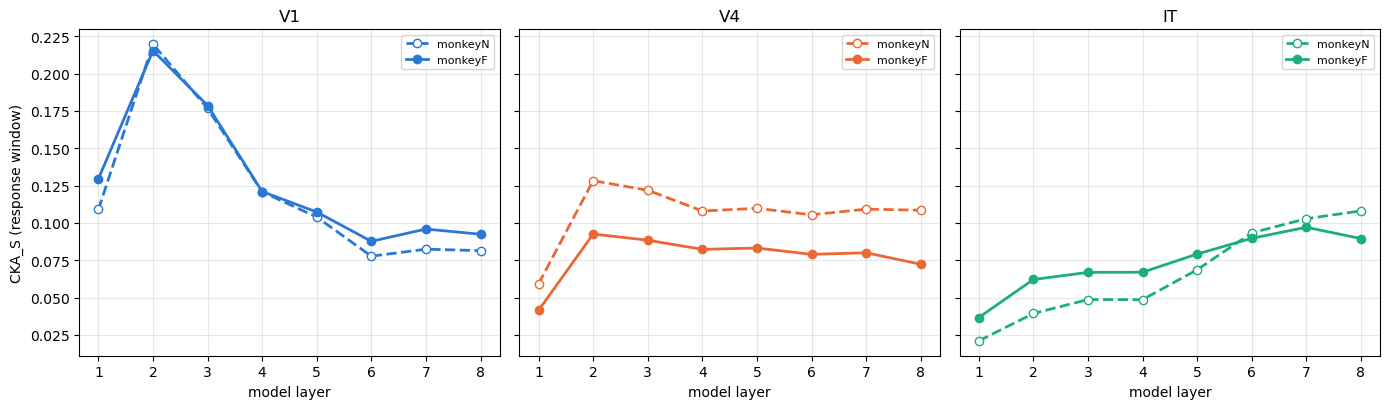

V1 monkeyN: best layer2 (0.220)   0.109  0.220  0.177  0.121  0.104  0.078  0.082  0.081
V1 monkeyF: best layer2 (0.215)   0.130  0.215  0.179  0.121  0.107  0.088  0.096  0.092
V4 monkeyN: best layer2 (0.128)   0.059  0.128  0.122  0.108  0.110  0.105  0.109  0.109
V4 monkeyF: best layer2 (0.093)   0.041  0.093  0.088  0.082  0.083  0.079  0.080  0.072
IT monkeyN: best layer8 (0.108)   0.021  0.039  0.049  0.049  0.069  0.093  0.103  0.108
IT monkeyF: best layer7 (0.097)   0.037  0.062  0.067  0.067  0.079  0.090  0.097  0.090


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
summary = {}
for m, style in [("monkeyN", "o--"), ("monkeyF", "o-")]:
    c = res[m]["cka_pooled"][..., S]
    summary[m] = np.array([[np.nanmean(c[i, j, window[a]]) for j, a in enumerate(areas)] for i in range(len(layers))])
    for j, area in enumerate(areas):
        axes[j].plot(range(1, 9), summary[m][:, j], style, color=area_color[area], lw=2, ms=6,
                     mfc="white" if m == "monkeyN" else area_color[area], label=m)
for j, area in enumerate(areas):
    axes[j].set(title=area, xlabel="model layer", xticks=range(1, 9))
    axes[j].grid(alpha=0.3)
    axes[j].legend(fontsize=8)
axes[0].set_ylabel("CKA_S (response window)")
plt.tight_layout()
plt.show()

for j, area in enumerate(areas):
    for m in ["monkeyN", "monkeyF"]:
        y = summary[m][:, j]
        print(f"{area} {m}: best {layers[int(np.nanargmax(y))]} ({np.nanmax(y):.3f})   " + "  ".join(f"{v:.3f}" for v in y))